# Diagnosing misspecification in the population

Three known structural systems separate omitted-common-cause bias, collider bias, and conditioning on a confounded mediator:

$$
\begin{aligned}
\text{Fork:}\quad &Z=\varepsilon_Z,\quad X=Z+\varepsilon_X,\quad Y=Z+\varepsilon_Y,\\
\text{Collider:}\quad &X=\varepsilon_X,\quad Y=\varepsilon_Y,\quad Z=X+Y+\varepsilon_Z,\\
\text{Confounded mediator:}\quad &X=\varepsilon_X,\quad W=\varepsilon_W,\quad Z=X+W+\varepsilon_Z,\quad Y=Z+W+\varepsilon_Y.
\end{aligned}
$$

Here, $X$ is the exposure, $Y$ is the outcome, $Z$ is respectively a common cause, a collider, or a mediator, $W$ is an unobserved common cause of the mediator and outcome, and every $\varepsilon$ is an independent standard-normal disturbance.

Row,Structure,Variable role,Specification,Exposure coefficient,Conditioning-variable coefficient,Explained variance
,String,String,String,Float64,Float64,Float64
1,Fork,Confounder,Conditioning variable omitted,0.5,NaN,0.25
2,Fork,Confounder,Conditioning variable included,0.0,1.0,0.5
3,Collider,Collider,Conditioning variable omitted,0.0,NaN,0.0
4,Collider,Collider,Conditioning variable included,-0.5,0.5,0.5
5,Confounded mediator,Confounded Mediator,Conditioning variable omitted,1.0,NaN,0.142857
6,Confounded mediator,Confounded Mediator,Conditioning variable included,-0.5,1.5,0.785714


Row,Structure,Specification,Exposure coefficient,Exposure standard error,Exposure test signal,Conditioning-variable coefficient,Explained variance,Adjusted explained variance,Residual variance,Observations,Seed
,String,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Int64,Int64
1,Fork,Conditioning variable omitted,0.496351,0.0122577,40.4929,NaN,0.247026,0.246875,1.46753,5000,0
2,Fork,Conditioning variable included,0.00072023,0.0141796,0.0507934,0.995713,0.494804,0.494602,0.984813,5000,0
3,Collider,Conditioning variable omitted,0.00150355,0.0142084,0.105821,NaN,2.24052e-6,-0.000197839,0.98001,5000,0
4,Collider,Conditioning variable included,-0.496296,0.0122831,-40.4046,0.498828,0.499189,0.498988,0.490899,5000,0
5,Confounded mediator,Conditioning variable omitted,1.0055,0.0346771,28.9962,NaN,0.143999,0.143828,5.83746,5000,0
6,Confounded mediator,Conditioning variable included,-0.481367,0.0212793,-22.6213,1.48994,0.784001,0.783915,1.47329,5000,0


Row,Structure,Manual omitted coefficient,Library omitted coefficient,Manual included coefficient,Library included coefficient,Maximum difference
,String,Float64,Float64,Float64,Float64,Float64
1,Fork,0.496351,0.496351,0.00072023,0.00072023,0.0
2,Collider,0.00150355,0.00150355,-0.496296,-0.496296,0.0
3,Confounded mediator,1.0055,1.0055,-0.481367,-0.481367,0.0


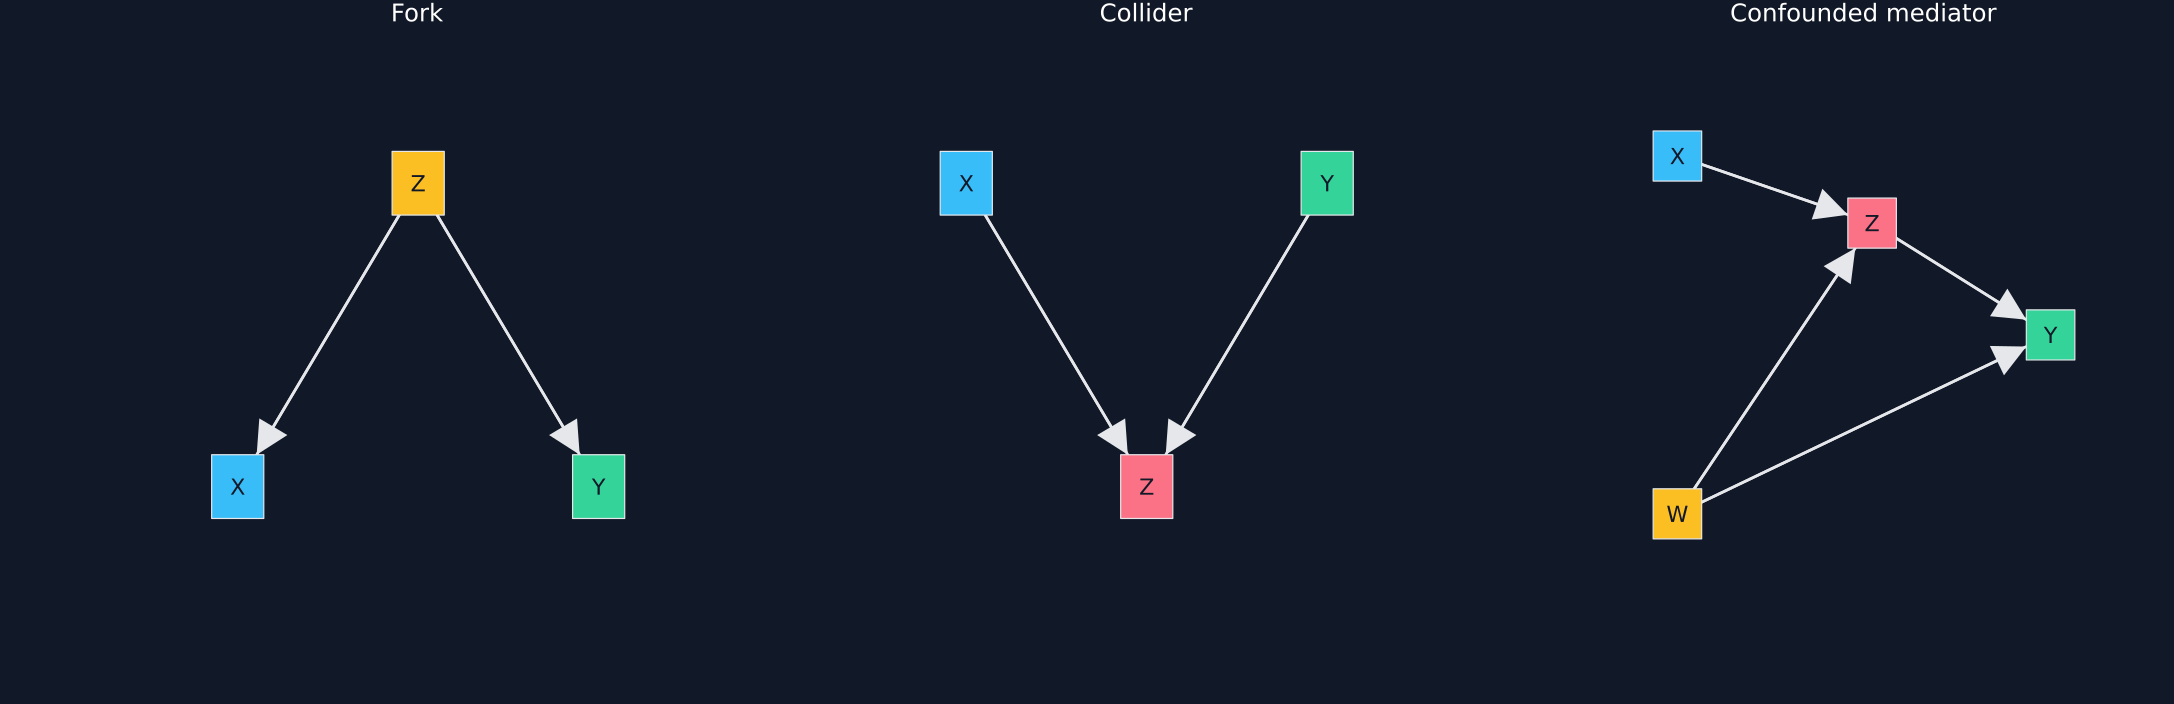

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("04_factor_mirage");
using CSV, TOML
using RiskLabAI.CausalFactorAnalysis
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy
include(joinpath("..","support","BookTreatmentStudy.jl"))
using .BookTreatmentStudy: histogram_peak
include(joinpath("..","support","BookMirageStudy.jl"))
using .BookMirageStudy
chapter_palette=(background="#111827",axes="#111827",text="#E5E7EB",cyan="#38BDF8",amber="#FBBF24",green="#34D399",rose="#FB7185",grid="#374151")
default(background_color=chapter_palette.background,background_color_inside=chapter_palette.axes,foreground_color=chapter_palette.text,gridcolor=chapter_palette.grid,fontfamily="sans-serif",left_margin=10Plots.mm,bottom_margin=10Plots.mm,titlefontsize=11,guidefontsize=10)
store=PrimitiveStore(joinpath("..","data","chapter04_random_inputs"),"mirage")
captions=Dict("confounder_standardized_coefficients"=>"Standardized omitted-confounder coefficients.","confounder_generated_check"=>"A visible fixed-seed confounder experiment.","confounder_general_variance"=>"Omitted coefficients with general positive variances.","confounder_return_examples"=>"Correct and omitted-confounder expected returns.","confounder_static_gap"=>"The exact fixed-link forecast-return gap.","confounder_zero_boundaries"=>"Exact coefficient and shifted-return sign boundaries.","confounder_input_checks"=>"Input-boundary checks for omitted-confounder calculations.","confounder_numerical_stability"=>"Finite-scaling and sign-preservation checks.","confounder_section_summary"=>"Main conclusions from the omitted-confounder experiments.","collider_standardized_coefficients"=>"Population coefficients after conditioning on the collider.","collider_generated_check"=>"A visible fixed-seed collider experiment.","collider_general_variance"=>"Collider-conditioned coefficients with general variances.","collider_return_examples"=>"Negative expected returns after collider conditioning.","collider_return_boundaries"=>"Exact equality and zero boundaries for collider returns.","collider_diagnostic_example"=>"Model-comparison quantities for the released Appendix example.","collider_adjusted_threshold"=>"The strict adjusted explained-variance threshold.","collider_expected_signals"=>"Expected coefficient signals under the population approximation.","collider_conditional_selection"=>"Marginal independence and collider-induced conditional association.","collider_input_checks"=>"Input-boundary checks for collider calculations.","collider_numerical_stability"=>"Finite-scaling and sign-preservation checks for collider calculations.","collider_section_summary"=>"Main conclusions from the collider experiments.","specification_population_targets"=>"Exact population targets for the three structural systems.","specification_seed_zero_samples"=>"Seed-zero sample diagnostics with 5,000 observations.","specification_visible_generation_parity"=>"Visible generation agrees with the released fixed-seed experiments.","specification_population_sample_gaps"=>"Population targets and seed-zero sample errors.","specification_repeated_convergence"=>"Repeated-sample convergence to the population coefficient targets.","specification_seed_variation"=>"Coefficient variation across fixed-seed generated samples.","specification_input_checks"=>"Invalid sample-size and seed checks for all three experiments.","specification_record_checks"=>"Repeatability and immutable-record checks.","specification_public_surface"=>"Released public records and functions covered by Chapter 26.","specification_section_summary"=>"How the three wrong specifications change the exposure coefficient.")
function table(values,name)
    shown=copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column]=ifelse.(shown[!,column],"Yes","No")
        end
    end
    save_table(shown,paths,name;caption=captions[name],label="tab:chapter26-"*replace(name,"_"=>"-"))
    return nothing
end
function assert_artifacts(figures,tables)
    @assert all(name->isfile(joinpath(paths.figures,name*".pdf")),figures)
    @assert all(name->isfile(joinpath(paths.tables,name*".tex")),tables)
end
function graph_panel(nodes,edges,positions,title)
    graph=DirectedGraph(nodes,edges)
    xs,ys=[positions[node][1] for node in graph.nodes],[positions[node][2] for node in graph.nodes]
    spanx,spany=max(maximum(xs)-minimum(xs),2.),max(maximum(ys)-minimum(ys),1.5)
    rx,ry=.065spanx,.07spany
    figure=plot(;title,legend=false,axis=false,grid=false,xlims=(minimum(xs)-.22spanx,maximum(xs)+.22spanx),ylims=(minimum(ys)-.28spany,maximum(ys)+.28spany),widen=false)
    for (left,right) in graph.edges
        x1,y1=positions[left]
        x2,y2=positions[right]
        dx,dy=x2-x1,y2-y1
        fraction=min(abs(dx)>0 ? rx/abs(dx) : Inf,abs(dy)>0 ? ry/abs(dy) : Inf,.42)
        plot!(figure,[x1+fraction*dx,x2-fraction*dx],[y1+fraction*dy,y2-fraction*dy];color=chapter_palette.text,linewidth=1.8,arrow=Plots.arrow(:closed,.14,.12),label="")
    end
    for node in graph.nodes
        x,y=positions[node]
        color=node=="X" ? chapter_palette.cyan : node=="Y" ? chapter_palette.green : node=="W" || (node=="Z" && ("Z","X") in graph.edges) ? chapter_palette.amber : chapter_palette.rose
        plot!(figure,Shape([x-rx,x+rx,x+rx,x-rx],[y-ry,y-ry,y+ry,y+ry]);fillcolor=color,linecolor=chapter_palette.text,linewidth=.8,label="")
        annotate!(figure,x,y,text(node,10,chapter_palette.background,:center))
    end
    return figure
end
structures=["Fork","Collider","Confounded mediator"]
population_functions=Dict("Fork"=>fork_population_diagnostics,"Collider"=>collider_population_diagnostics,"Confounded mediator"=>confounded_mediator_population_diagnostics)
experiment_functions=Dict("Fork"=>fork_specification_experiment,"Collider"=>collider_specification_experiment,"Confounded mediator"=>confounded_mediator_specification_experiment)
population_rows,sample_rows,parity_rows=Tuple[],Tuple[],Tuple[]
for (index,structure) in enumerate(structures)
    population=population_functions[structure]()
    experiment=shared_experiment(experiment_functions[structure],store,5000,0)
    values=generated_values(structure,primitive_sample(store,5000,0))
    manual_unconditioned=manual_diagnostics(values.Y,[values.X],["X"])
    manual_conditioned=manual_diagnostics(values.Y,[values.X,values.Z],["X","Z"])
    for (specification,population_diagnostics,sample_diagnostics) in [("Conditioning variable omitted",population.unconditioned,experiment.unconditioned),("Conditioning variable included",population.conditioned,experiment.conditioned)]
        role=titlecase(replace(population.conditioning_variable_role,"_"=>" "))
        population_z="Z" in population_diagnostics.coefficient_names ? coefficient_value(population_diagnostics,"Z") : NaN
        sample_z="Z" in sample_diagnostics.coefficient_names ? coefficient_value(sample_diagnostics,"Z") : NaN
        push!(population_rows,(structure,role,specification,coefficient_value(population_diagnostics,"X"),population_z,population_diagnostics.r_squared))
        push!(sample_rows,(structure,specification,coefficient_value(sample_diagnostics,"X"),sample_diagnostics.standard_errors[2],sample_diagnostics.t_statistics[2],sample_z,sample_diagnostics.r_squared,sample_diagnostics.adjusted_r_squared,sample_diagnostics.residual_variance,sample_diagnostics.n_observations,0))
    end
    manual_omitted,manual_included=manual_unconditioned.coefficients[2],manual_conditioned.coefficients[2]
    library_omitted,library_included=experiment.unconditioned.coefficients[2],experiment.conditioned.coefficients[2]
    push!(parity_rows,(structure,manual_omitted,library_omitted,manual_included,library_included,max(abs(manual_omitted-library_omitted),abs(manual_included-library_included))))
    save_data(values,paths,"specification_generated_values_"*string(index))
end
population_table=frame(["Structure","Variable role","Specification","Exposure coefficient","Conditioning-variable coefficient","Explained variance"],population_rows)
sample_table=frame(["Structure","Specification","Exposure coefficient","Exposure standard error","Exposure test signal","Conditioning-variable coefficient","Explained variance","Adjusted explained variance","Residual variance","Observations","Seed"],sample_rows)
parity_table=frame(["Structure","Manual omitted coefficient","Library omitted coefficient","Manual included coefficient","Library included coefficient","Maximum difference"],parity_rows)
table(population_table,"specification_population_targets")
table(sample_table,"specification_seed_zero_samples")
table(parity_table,"specification_visible_generation_parity")
fork_graph=graph_panel(["Z","X","Y"],[("Z","X"),("Z","Y")],Dict("Z"=>(.9,1.),"X"=>(0.,0.),"Y"=>(1.8,0.)),"Fork")
collider_graph=graph_panel(["X","Y","Z"],[("X","Z"),("Y","Z")],Dict("X"=>(0.,0.),"Y"=>(1.8,0.),"Z"=>(.9,-1.)),"Collider")
mediator_graph=graph_panel(["X","W","Z","Y"],[("X","Z"),("W","Z"),("W","Y"),("Z","Y")],Dict("X"=>(0.,.8),"W"=>(0.,-.8),"Z"=>(1.2,.5),"Y"=>(2.3,0.)),"Confounded mediator")
save_figure(plot(fork_graph,collider_graph,mediator_graph;layout=(1,3),size=(1450,470)),paths,"specification_three_graphs")


## Reproducing population targets in fixed samples

For centered predictors collected in the vector $Q$, the population least-squares target and explained variance are:

$$
b^{\star}=\Sigma_{QQ}^{-1}\Sigma_{QY},
\qquad
R^2=\frac{\Sigma_{QY}^{\mathsf T}\Sigma_{QQ}^{-1}\Sigma_{QY}}{\sigma_Y^2}.
$$

Here, $b^{\star}$ is the population slope vector, $\Sigma_{QQ}$ is the predictor covariance matrix, $\Sigma_{QY}$ is the predictor-outcome covariance vector, $\sigma_Y^2$ is the outcome variance, and $R^2$ is the population explained-variance fraction.

Row,Structure,Specification,Population exposure coefficient,Sample exposure coefficient,Coefficient error,Population explained variance,Sample explained variance,Explained-variance error
,String,String,Float64,Float64,Float64,Float64,Float64,Float64
1,Fork,Conditioning variable omitted,0.5,0.496351,-0.00364876,0.25,0.247026,-0.00297424
2,Fork,Conditioning variable included,0.0,0.00072023,0.00072023,0.5,0.494804,-0.00519601
3,Collider,Conditioning variable omitted,0.0,0.00150355,0.00150355,0.0,2.24052e-6,2.24052e-6
4,Collider,Conditioning variable included,-0.5,-0.496296,0.00370416,0.5,0.499189,-0.000811319
5,Confounded mediator,Conditioning variable omitted,1.0,1.0055,0.00550255,0.142857,0.143999,0.00114202
6,Confounded mediator,Conditioning variable included,-0.5,-0.481367,0.0186334,0.785714,0.784001,-0.00171321


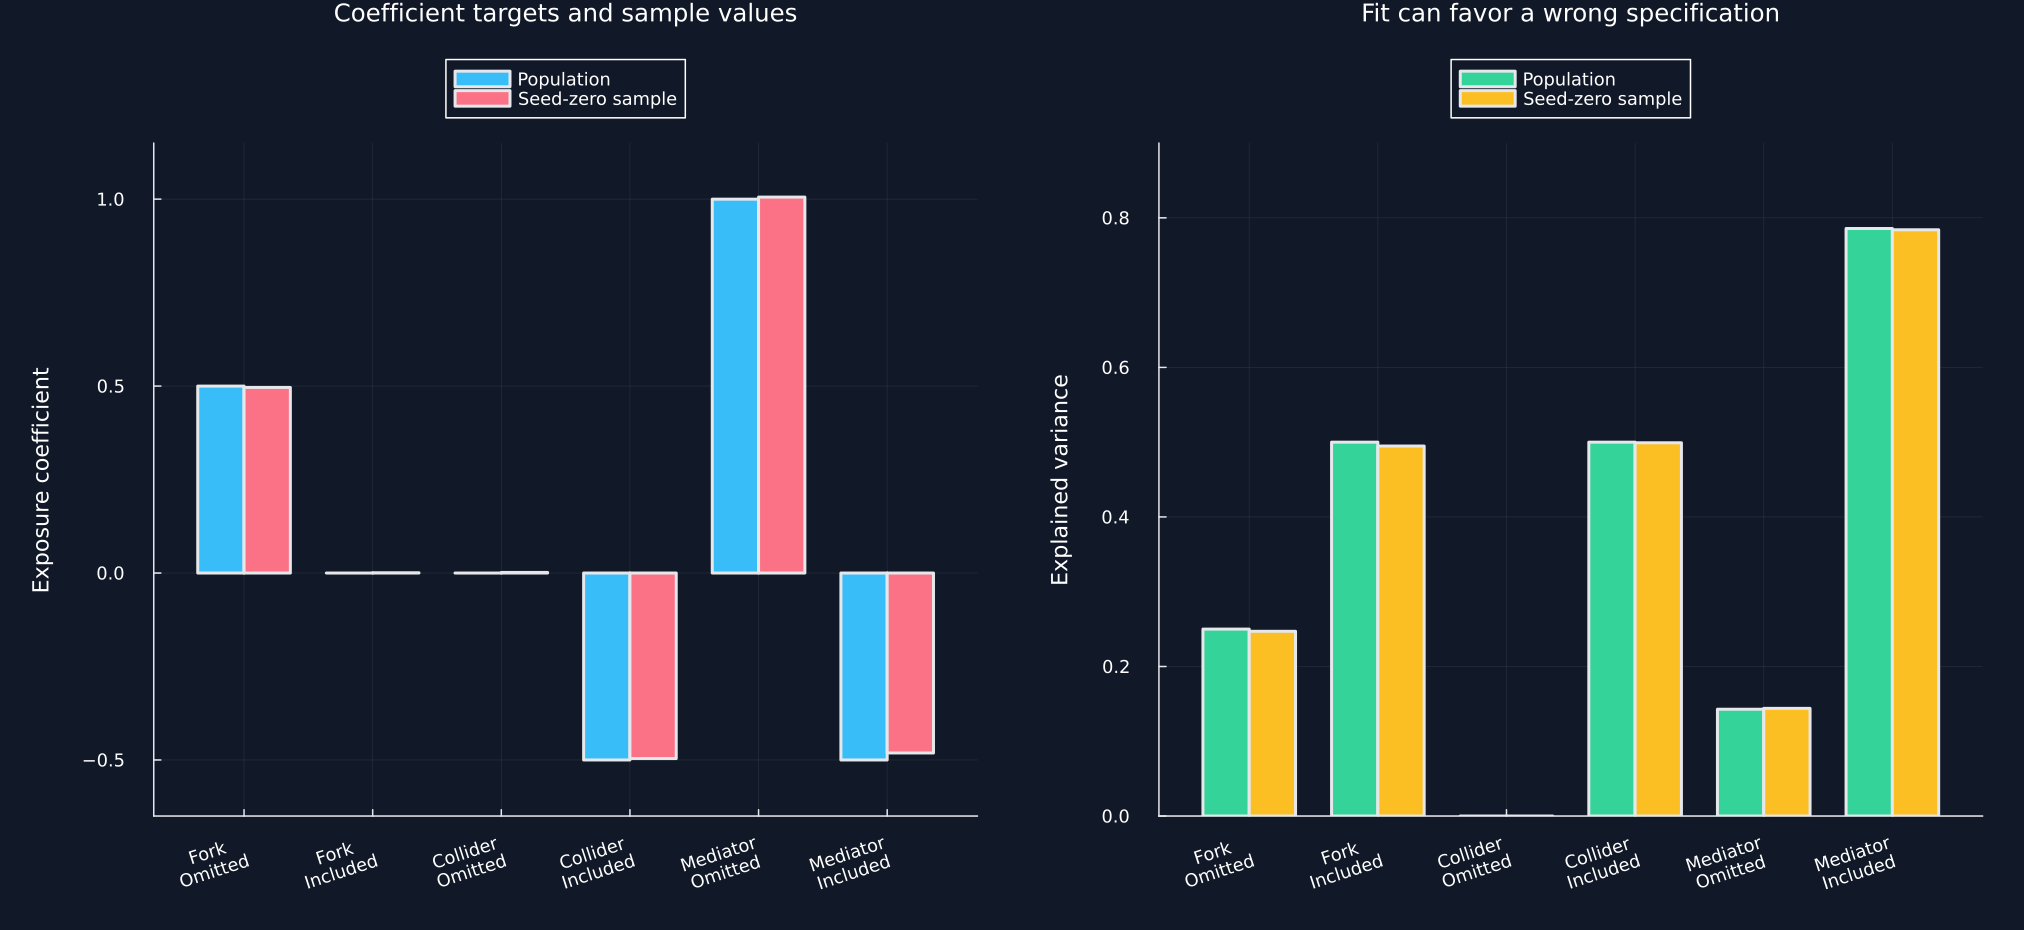

In [2]:
gap_rows=Tuple[]
for structure in structures
    population=population_functions[structure]()
    experiment=shared_experiment(experiment_functions[structure],store)
    for (specification,population_diagnostics,sample_diagnostics) in [("Conditioning variable omitted",population.unconditioned,experiment.unconditioned),("Conditioning variable included",population.conditioned,experiment.conditioned)]
        target=coefficient_value(population_diagnostics,"X")
        estimate=coefficient_value(sample_diagnostics,"X")
        push!(gap_rows,(structure,specification,target,estimate,estimate-target,population_diagnostics.r_squared,sample_diagnostics.r_squared,sample_diagnostics.r_squared-population_diagnostics.r_squared))
    end
end
gap_table=frame(["Structure","Specification","Population exposure coefficient","Sample exposure coefficient","Coefficient error","Population explained variance","Sample explained variance","Explained-variance error"],gap_rows)
table(gap_table,"specification_population_sample_gaps")
labels=[replace(row.Structure,"Confounded mediator"=>"Mediator")*"
"*titlecase(replace(row.Specification,"Conditioning variable "=>"")) for row in eachrow(gap_table)]
positions=collect(1:6)
coefficient_panel=bar(positions.-.18,gap_table[!,"Population exposure coefficient"];bar_width=.36,color=chapter_palette.cyan,label="Population",xticks=(positions,labels),xrotation=18,ylabel="Exposure coefficient",title="Coefficient targets and sample values",legend=:outertop)
bar!(coefficient_panel,positions.+.18,gap_table[!,"Sample exposure coefficient"];bar_width=.36,color=chapter_palette.rose,label="Seed-zero sample")
fit_panel=bar(positions.-.18,gap_table[!,"Population explained variance"];bar_width=.36,color=chapter_palette.green,label="Population",xticks=(positions,labels),xrotation=18,ylabel="Explained variance",title="Fit can favor a wrong specification",legend=:outertop)
bar!(fit_panel,positions.+.18,gap_table[!,"Sample explained variance"];bar_width=.36,color=chapter_palette.amber,label="Seed-zero sample")
plot!(coefficient_panel;ylims=(-.65,1.15))
plot!(fit_panel;ylims=(0.,.9))
save_figure(plot(coefficient_panel,fit_panel;layout=(1,2),size=(1350,620)),paths,"specification_population_sample_comparison")


## Checking convergence across repeated samples

Across $M$ generated samples, coefficient bias and root mean squared error are measured by:

$$
\widehat B_M
=\frac{1}{M}\sum_{m=1}^{M}(\widehat b_m-b^{\star}),
\qquad
\widehat{\operatorname{RMSE}}_M
=\sqrt{\frac{1}{M}\sum_{m=1}^{M}(\widehat b_m-b^{\star})^2}.
$$

Here, $M$ is the number of repeated generated samples, $\widehat b_m$ is the exposure coefficient in repetition $m$, $b^{\star}$ is its population target under the chosen specification, $\widehat B_M$ is estimated bias, and $\widehat{\operatorname{RMSE}}_M$ is estimated root mean squared error.

Row,Structure,Specification,Observations,Repetitions,Population coefficient,Mean coefficient,Bias,Root mean squared error,Coefficient standard deviation,Mean explained variance
,String,String,Int64,Int64,Float64,Float64,Float64,Float64,Float64,Float64
1,Fork,Omitted,50,30,0.5,0.518872,0.0188724,0.102567,0.102539,0.281497
2,Fork,Omitted,200,30,0.5,0.517938,0.0179383,0.0651,0.0636496,0.259755
3,Fork,Omitted,1000,30,0.5,0.494737,-0.00526333,0.0396816,0.0400034,0.248121
4,Fork,Omitted,5000,30,0.5,0.498641,-0.00135872,0.0158371,0.0160484,0.24807
5,Fork,Included,50,30,0.0,0.00536792,0.00536792,0.128841,0.13093,0.540203
6,Fork,Included,200,30,0.0,0.00905438,0.00905438,0.0764203,0.0771793,0.51267
7,Fork,Included,1000,30,0.0,-0.00544324,-0.00544324,0.0355059,0.035686,0.499761
8,Fork,Included,5000,30,0.0,-0.00361001,-0.00361001,0.0111378,0.0107167,0.499046
9,Collider,Omitted,50,30,0.0,0.0264444,0.0264444,0.151985,0.152226,0.0238364


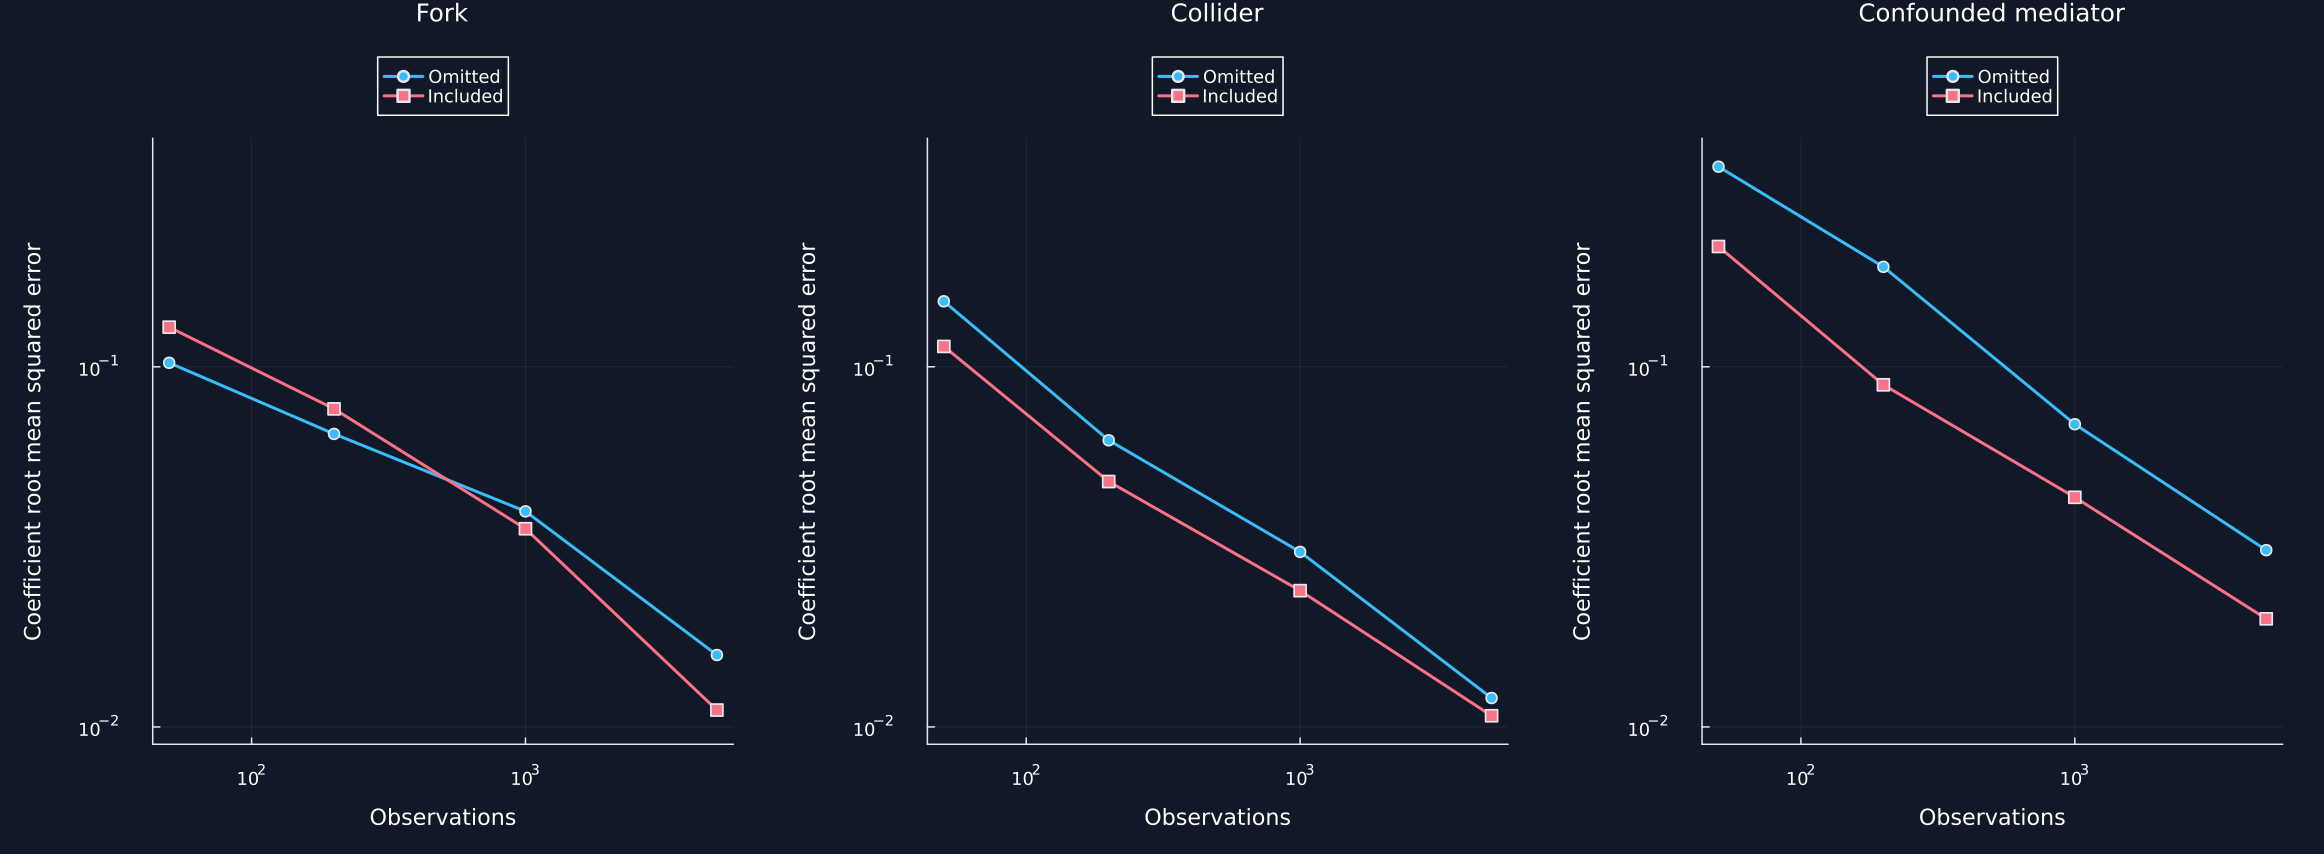

In [3]:
sample_sizes=[50,200,1000,5000]
repetitions=30
convergence_rows,repeat_rows=Tuple[],Tuple[]
stored_estimates=Dict{Tuple{String,String,Int},Vector{Float64}}()
for structure in structures
    population=population_functions[structure]()
    for (specification,population_diagnostics) in [("Omitted",population.unconditioned),("Included",population.conditioned)]
        target=coefficient_value(population_diagnostics,"X")
        for observations in sample_sizes
            estimates,explained_values=Float64[],Float64[]
            for seed in 0:repetitions-1
                result=shared_experiment(experiment_functions[structure],store,observations,seed)
                diagnostics=specification=="Omitted" ? result.unconditioned : result.conditioned
                push!(estimates,coefficient_value(diagnostics,"X"))
                push!(explained_values,diagnostics.r_squared)
                z=length(diagnostics.coefficients)==3 ? diagnostics.coefficients[3] : NaN
                z_se=length(diagnostics.standard_errors)==3 ? diagnostics.standard_errors[3] : NaN
                z_t=length(diagnostics.t_statistics)==3 ? diagnostics.t_statistics[3] : NaN
                push!(repeat_rows,(structure,specification,observations,seed,diagnostics.coefficients[1],diagnostics.standard_errors[1],diagnostics.t_statistics[1],diagnostics.coefficients[2],diagnostics.standard_errors[2],diagnostics.t_statistics[2],z,z_se,z_t,diagnostics.r_squared,diagnostics.adjusted_r_squared,diagnostics.residual_variance))
            end
            stored_estimates[(structure,specification,observations)]=estimates
            push!(convergence_rows,(structure,specification,observations,repetitions,target,mean(estimates),mean(estimates)-target,sqrt(mean(abs2,estimates.-target)),std(estimates),mean(explained_values)))
        end
    end
end
convergence_table=frame(["Structure","Specification","Observations","Repetitions","Population coefficient","Mean coefficient","Bias","Root mean squared error","Coefficient standard deviation","Mean explained variance"],convergence_rows)
table(convergence_table,"specification_repeated_convergence")
save_data(frame(["Structure","Specification","Observations","Seed","Intercept","Intercept standard error","Intercept test signal","Exposure coefficient","Exposure standard error","Exposure test signal","Conditioning coefficient","Conditioning standard error","Conditioning test signal","Explained variance","Adjusted explained variance","Residual variance"],repeat_rows),paths,"specification_repeated_diagnostics")
panels=Plots.Plot[]
limits=extrema(convergence_table[!,"Root mean squared error"])
for structure in structures
    panel=plot(;xscale=:log10,yscale=:log10,xlabel="Observations",ylabel="Coefficient root mean squared error",title=structure,ylims=(limits[1]/1.2,limits[2]*1.2),legend=:outertop)
    for (specification,color,marker) in [("Omitted",chapter_palette.cyan,:circle),("Included",chapter_palette.rose,:rect)]
        rows=convergence_table[(convergence_table.Structure.==structure).&(convergence_table.Specification.==specification),:]
        plot!(panel,rows.Observations,rows[!,"Root mean squared error"];color,marker,linewidth=2,label=specification)
    end
    push!(panels,panel)
end
save_figure(plot(panels...;layout=(1,3),size=(1550,570)),paths,"specification_convergence")


## Sampling variation does not settle the graph

Within a fixed declared model and specification, the sample coefficient approaches its population regression target:

$$
\widehat b_n\xrightarrow{p}b^{\star}
\qquad\text{as}\qquad n\to\infty.
$$

Here, $\widehat b_n$ is the sample exposure coefficient from $n$ observations, $b^{\star}$ is the population regression coefficient for that specification, and $\xrightarrow{p}$ denotes convergence in probability; the limit can still be noncausal when the specification conditions on the wrong variable or omits a required one.

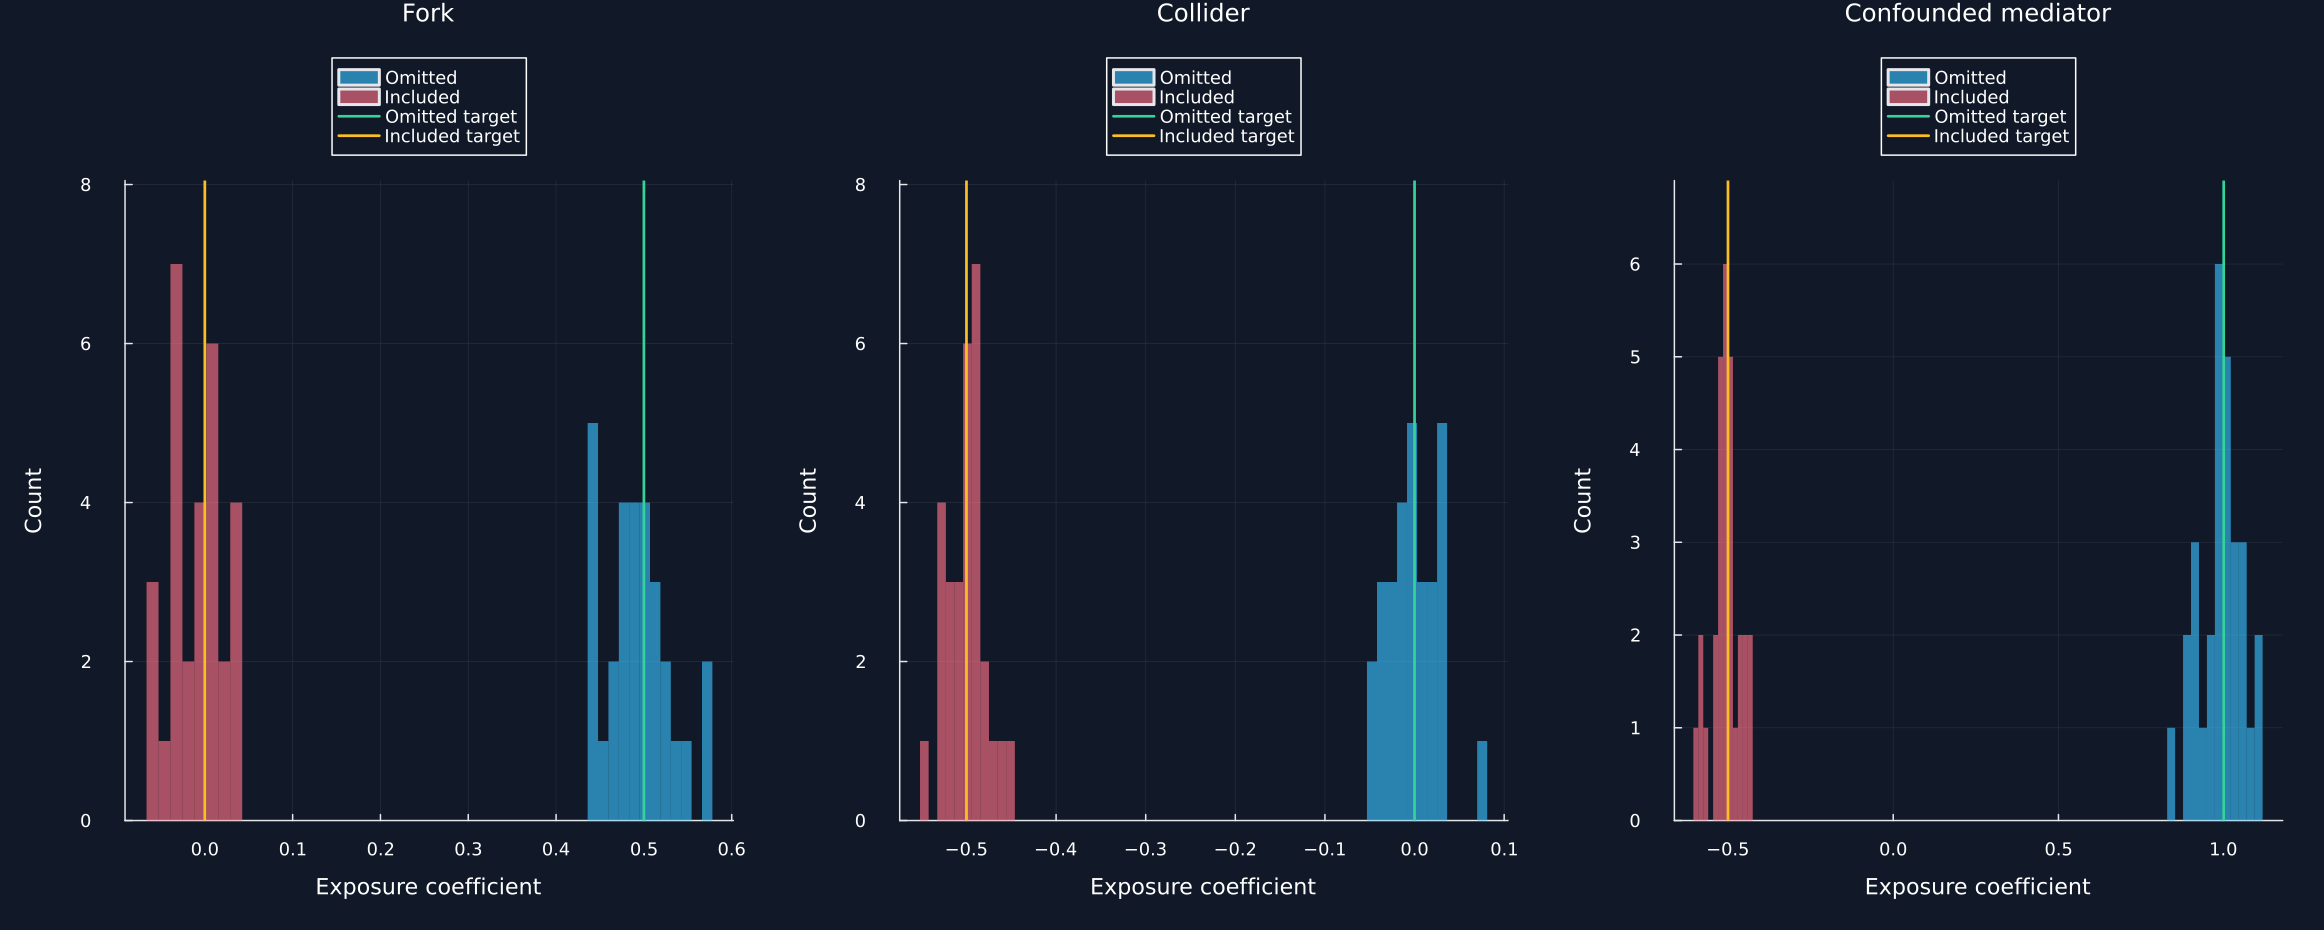

Row,Structure,Specification,Observations,Seeds,Population coefficient,Mean coefficient,Standard deviation,Smallest coefficient,Largest coefficient
,String,String,Int64,Int64,Float64,Float64,Float64,Float64,Float64
1,Fork,Omitted,1000,30,0.5,0.494737,0.0400034,0.435943,0.578
2,Fork,Included,1000,30,0.0,-0.00544324,0.035686,-0.0663567,0.0970274
3,Collider,Omitted,1000,30,0.0,0.0027377,0.0310175,-0.053095,0.0810556
4,Collider,Included,1000,30,-0.5,-0.497561,0.024178,-0.551832,-0.436417
5,Confounded mediator,Omitted,1000,30,1.0,0.995305,0.0702848,0.82896,1.11774
6,Confounded mediator,Included,1000,30,-0.5,-0.503815,0.0439837,-0.60474,-0.425111


In [4]:
seed_summary_rows=Tuple[]
panels=Plots.Plot[]
for structure in structures
    omitted=stored_estimates[(structure,"Omitted",1000)]
    included=stored_estimates[(structure,"Included",1000)]
    population=population_functions[structure]()
    omitted_target=coefficient_value(population.unconditioned,"X")
    included_target=coefficient_value(population.conditioned,"X")
    for (specification,values,target) in [("Omitted",omitted,omitted_target),("Included",included,included_target)]
        push!(seed_summary_rows,(structure,specification,1000,repetitions,target,mean(values),std(values),minimum(values),maximum(values)))
    end
    omitted_bins=collect(range(minimum(omitted),maximum(omitted);length=13))
    included_bins=collect(range(minimum(included),maximum(included);length=13))
    peak=max(histogram_peak(omitted,omitted_bins),histogram_peak(included,included_bins))
    panel=histogram(omitted;bins=omitted_bins,color=chapter_palette.cyan,alpha=.65,linealpha=0,label="Omitted",xlabel="Exposure coefficient",ylabel="Count",title=structure,ylims=(0,1.15peak),legend=:outertop)
    histogram!(panel,included;bins=included_bins,color=chapter_palette.rose,alpha=.65,linealpha=0,label="Included")
    vline!(panel,[omitted_target];color=chapter_palette.green,linewidth=1.8,label="Omitted target")
    vline!(panel,[included_target];color=chapter_palette.amber,linewidth=1.8,label="Included target")
    push!(panels,panel)
end
save_figure(plot(panels...;layout=(1,3),size=(1550,620)),paths,"specification_seed_distributions")
seed_summary_table=frame(["Structure","Specification","Observations","Seeds","Population coefficient","Mean coefficient","Standard deviation","Smallest coefficient","Largest coefficient"],seed_summary_rows)
table(seed_summary_table,"specification_seed_variation")


## Preserving a repeatable calculation record

In [5]:
invalid_cases=[(3,0,"3","0"),(true,0,"True","0"),(4.5,0,"4.5","0"),(1000001,0,"1000001","0"),(10,true,"10","True"),(10,-1,"10","-1"),(10,2^32,"10","4294967296")]
validity_rows=Tuple[]
for structure in structures
    function_value=experiment_functions[structure]
    for (observations,seed,count_text,seed_text) in invalid_cases
        result=contract_result(structure*": sample="*count_text*", seed="*seed_text,()->function_value(observations,seed),ArgumentError)
        push!(validity_rows,(structure,result...))
    end
end
validity_table=frame(["Structure","Check","Expected result","Observed result","Passed"],validity_rows)
table(validity_table,"specification_input_checks")
first=shared_experiment(fork_specification_experiment,store,200,17)
second=shared_experiment(fork_specification_experiment,store,200,17)
different=shared_experiment(fork_specification_experiment,store,200,18)
immutable_population=fork_population_diagnostics()
immutable_sample=shared_experiment(fork_specification_experiment,store,20,3)
record_rows=Tuple[("Same seed and size give the same record",same_record(first,second),missing,missing),("A different seed changes the record",!same_record(first,different),missing,missing),("Population result has no mutable attribute dictionary",!ismutabletype(typeof(immutable_population)),missing,missing),("Sample result has no mutable attribute dictionary",!ismutabletype(typeof(immutable_sample)),missing,missing)]
for (name,action) in [("Frozen strategy-performance record",()->setproperty!(collider_forecast_return(1.,1.,2.),:correct,0.)),("Immutable population tuple record",()->setproperty!(immutable_population,:structure,"changed")),("Immutable sample tuple record",()->setproperty!(immutable_sample,:structure,"changed"))]
    result=contract_result(name,action,ErrorException)
    push!(record_rows,(result[1],result[4],result[2],result[3]))
end
record_table=frame(["Check","Passed","Expected result","Observed result"],record_rows)
table(record_table,"specification_record_checks")
public_records=[StrategyPerformance,ColliderCoefficients,ColliderDiagnostics,PopulationRegressionDiagnostics,RegressionDiagnostics,SpecificationExperimentResult,SpecificationPopulationResult]
public_functions=[confounder_undercontrolled_coefficient,generalized_confounder_undercontrolled_coefficient,confounder_factor_return,confounder_forecast_return,collider_overcontrolled_coefficients,generalized_collider_overcontrolled_coefficients,collider_factor_return,collider_forecast_return,collider_model_diagnostics,fork_population_diagnostics,collider_population_diagnostics,confounded_mediator_population_diagnostics,fork_specification_experiment,collider_specification_experiment,confounded_mediator_specification_experiment]
surface_table=frame(["Public group","Count","Names"],[("Result records",length(public_records),join(string.(nameof.(public_records)),", ")),("Functions",length(public_functions),join(string.(nameof.(public_functions)),", ")),("Total Chapter 26 surface",length(public_records)+length(public_functions),"All listed records and functions")])
table(surface_table,"specification_public_surface")
section_summary = frame(["Structure","Wrong choice","Population exposure coefficient after wrong choice","Causal interpretation"],[["Fork","Omit the common cause",0.5,"Noncausal association"],["Collider","Include the common outcome",-0.5,"Selection-induced association"],["Confounded mediator","Include the confounded mediator",-0.5,"Blocked effect plus opened path"]])
table(section_summary,"specification_section_summary")
@assert same_record(fork_specification_experiment(200,17),fork_specification_experiment(200,17))
@assert !same_record(fork_specification_experiment(200,17),fork_specification_experiment(200,18))


Row,Structure,Check,Expected result,Observed result,Passed
,String,String,String,String,String
1,Fork,"Fork: sample=3, seed=0",Rejected,Rejected,Yes
2,Fork,"Fork: sample=True, seed=0",Rejected,Rejected,Yes
3,Fork,"Fork: sample=4.5, seed=0",Rejected,Rejected,Yes
4,Fork,"Fork: sample=1000001, seed=0",Rejected,Rejected,Yes
5,Fork,"Fork: sample=10, seed=True",Rejected,Rejected,Yes
6,Fork,"Fork: sample=10, seed=-1",Rejected,Rejected,Yes
7,Fork,"Fork: sample=10, seed=4294967296",Rejected,Rejected,Yes
8,Collider,"Collider: sample=3, seed=0",Rejected,Rejected,Yes
9,Collider,"Collider: sample=True, seed=0",Rejected,Rejected,Yes


Row,Check,Passed,Expected result,Observed result
,String,String,String?,String?
1,Same seed and size give the same record,Yes,missing,missing
2,A different seed changes the record,Yes,missing,missing
3,Population result has no mutable attribute dictionary,Yes,missing,missing
4,Sample result has no mutable attribute dictionary,Yes,missing,missing
5,Frozen strategy-performance record,Yes,Rejected,Rejected
6,Immutable population tuple record,Yes,Rejected,Rejected
7,Immutable sample tuple record,Yes,Rejected,Rejected


Row,Public group,Count,Names
,String,Int64,String
1,Result records,7,"StrategyPerformance, ColliderCoefficients, ColliderDiagnostics, PopulationRegressionDiagnostics, RegressionDiagnostics, SpecificationExperimentResult, SpecificationPopulationResult"
2,Functions,15,"confounder_undercontrolled_coefficient, generalized_confounder_undercontrolled_coefficient, confounder_factor_return, confounder_forecast_return, collider_overcontrolled_coefficients, generalized_collider_overcontrolled_coefficients, collider_factor_return, collider_forecast_return, collider_model_diagnostics, fork_population_diagnostics, collider_population_diagnostics, confounded_mediator_population_diagnostics, fork_specification_experiment, collider_specification_experiment, confounded_mediator_specification_experiment"
3,Total Chapter 26 surface,22,All listed records and functions


Row,Structure,Wrong choice,Population exposure coefficient after wrong choice,Causal interpretation
,String,String,Float64,String
1,Fork,Omit the common cause,0.5,Noncausal association
2,Collider,Include the common outcome,-0.5,Selection-induced association
3,Confounded mediator,Include the confounded mediator,-0.5,Blocked effect plus opened path


## Tests

In [6]:
@assert fork_population_diagnostics().unconditioned.coefficients==(0.,.5)
@assert fork_population_diagnostics().conditioned.coefficients==(0.,0.,1.)
@assert collider_population_diagnostics().conditioned.coefficients==(0.,-.5,.5)
@assert confounded_mediator_population_diagnostics().unconditioned.r_squared==1/7
@assert confounded_mediator_population_diagnostics().conditioned.r_squared==11/14
@assert maximum(parity_table[!,"Maximum difference"])<1e-12
@assert all(validity_table.Passed)
@assert all(record_table.Passed)
@assert surface_table[surface_table[!,"Public group"].=="Total Chapter 26 surface","Count"][1]==22
@assert fork_population_diagnostics() isa SpecificationPopulationResult
@assert fork_population_diagnostics().conditioned isa PopulationRegressionDiagnostics
@assert shared_experiment(fork_specification_experiment,store,20,3) isa SpecificationExperimentResult
@assert shared_experiment(fork_specification_experiment,store,20,3).conditioned isa RegressionDiagnostics
assert_artifacts(["specification_three_graphs","specification_population_sample_comparison","specification_convergence","specification_seed_distributions"],["specification_population_targets","specification_seed_zero_samples","specification_visible_generation_parity","specification_population_sample_gaps","specification_repeated_convergence","specification_seed_variation","specification_input_checks","specification_record_checks","specification_public_surface","specification_section_summary"])
